# How many soul mates do you need?

The soul mate premise gives each person one possible partner in a pool of about 1.3 billion. The How Couples Meet and Stay Together survey (HCMST, Rosenfeld and colleagues, Stanford) shows how many people actually have had a partner by each age. This notebook asks how large the number of possible partners has to be for the two to match.

To get the data, read and accept the data use agreement on https://data.stanford.edu/hcmst2017, then save `HCMST 2017 to 2022 small public version 2.2.dta` to `data/raw/`. The agreement asks you to tell the HCMST contact person about your work and to cite the data.

Data citation: Rosenfeld, Michael J., Reuben J. Thomas, and Sonia Hausen. 2023. How Couples Meet and Stay Together 2017-2020-2022 combined dataset. [Computer files]. Stanford, CA: Stanford University Libraries. https://data.stanford.edu/hcmst2017

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from soulmates.hcmst import load_hcmst
from soulmates.match import build_match_model, build_soulmate_model, lifetime_curve
from soulmates.model import build_model, recog_prior
from soulmates.polymod import load_polymod
from soulmates.wpp import pool_size

hcmst = load_hcmst("../data/raw/HCMST 2017 to 2022 small public version 2.2.dta")
bands = pd.cut(hcmst["age"], [17, 24, 29, 34, 39, 49, 60])
observed = hcmst.groupby(bands, observed=True).apply(lambda g: pd.Series({
    "people": len(g),
    "never had a partner": int((~g["ever_partnered"]).sum()),
    "ever, share": g["ever_partnered"].mean(),
    "ever, weighted share": np.average(g["ever_partnered"], weights=g["weight"]),
})).astype({"people": int, "never had a partner": int})
observed.round(3)

,people,never had a partner,"ever, share","ever, weighted share"
age,,,,
"(17, 24]",254,49,0.807,0.768
"(24, 29]",410,31,0.924,0.910
"(29, 34]",251,3,0.988,0.985
"(34, 39]",272,7,0.974,0.970
"(39, 49]",505,5,0.990,0.990
"(49, 60]",828,3,0.996,0.996


## New people met by each age

N(a) is the number of new people you have met and talked to from age 15 up to age a. It comes from the POLYMOD fit of notebook 02, through the posterior means of the band means and the weekend effect.

In [2]:
polymod = load_polymod("../data/raw")
with build_model(polymod):
    contacts = pm.sample(random_seed=2, progressbar=False)
curve = lifetime_curve(contacts.posterior, start_age=15)
print({age: round(curve[age]) for age in (18, 25, 40, 60)})

no part_age: 65 of 7290 rows (0.9%)
no dayofweek: 136 of 7290 rows (1.9%)
no frequency_multi: 1407 of 97904 rows (1.4%)


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, beta_weekend, alpha, p_recog]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 34 seconds.


{18: 1420, 25: 5044, 40: 12794, 60: 21722}


## The free model

Each new person you talk to is a possible partner with chance q. The chance of having had a partner by age a is 1 − (1 − q) ^ N(a). The prior on q is wide, from 1 in 100 million to near certain.

In [3]:
with build_match_model(hcmst, curve):
    free = pm.sample(random_seed=2, idata_kwargs={"log_likelihood": True})
q = free.posterior["q"].values.ravel()
print(f"q: 1 in {1 / np.median(q):,.0f}, 94% interval 1 in {1 / np.percentile(q, 97):,.0f} "
      f"to 1 in {1 / np.percentile(q, 3):,.0f}, divergences {int(free.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [log10_q]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


q: 1 in 2,419, 94% interval 1 in 2,230 to 1 in 2,609, divergences 0


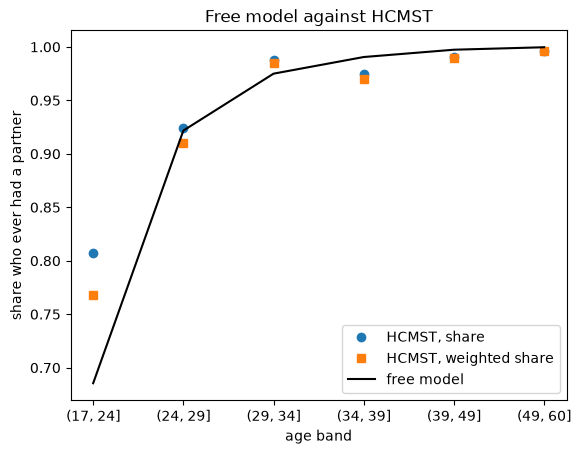

In [4]:
chance = 1 - (1 - q[:, None]) ** curve[hcmst["age"].to_numpy()][None, :]
predicted = pd.Series(chance.mean(axis=0)).groupby(bands.to_numpy(), observed=True).mean()
labels = [str(b) for b in observed.index]
fig, ax = plt.subplots()
ax.plot(labels, observed["ever, share"], "o", label="HCMST, share")
ax.plot(labels, observed["ever, weighted share"], "s", label="HCMST, weighted share")
ax.plot(labels, predicted.values, "k-", label="free model")
ax.set(xlabel="age band", ylabel="share who ever had a partner", title="Free model against HCMST")
ax.legend();

## The soul mate model

Now the premise itself: one possible partner in the world pool M, recognized with chance p_recog. Then q = p_recog / M. p_recog keeps the guess from notebook 02, 90% sure between 0.1 and 0.6.

In [5]:
wpp = pd.read_csv("../data/wpp_pool.csv")
M = pool_size(wpp)
with build_soulmate_model(hcmst, curve, M):
    soulmate = pm.sample(random_seed=2, idata_kwargs={"log_likelihood": True})
share = (1 - (1 - soulmate.posterior["q"].values.ravel()[:, None]) ** curve[hcmst["age"].to_numpy()][None, :]).mean()
print(f"soul mate model: predicted share who ever had a partner {share:.1e}, observed {hcmst['ever_partnered'].mean():.3f}")
print(f"divergences {int(soulmate.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


soul mate model: predicted share who ever had a partner 9.7e-06, observed 0.961
divergences 0


## Which model predicts better?

LOO (leave one out cross validation) scores how well each model predicts each person it did not see. elpd is that score summed over people, and higher is better.

In [6]:
comparison = az.compare({"free q": free, "one soul mate": soulmate})
comparison

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
free q,0,0.0,0.0,NaN,,,1.5,-350.0,29.0,1.0
one soul mate,1,-27900.0,140.0,1.0,,,0.0,-28200.0,120.0,0.0


## How many soul mates?

K = q × M / p_recog is the number of people in the world pool who would have worked for you. q comes from the free model, and p_recog from its prior, because no data informs it.

In [7]:
a, b = recog_prior()
p_recog = np.random.default_rng(4).beta(a, b, size=q.size)
K = q * M / p_recog
print(f"1 in {1 / np.median(q):,.0f} new people you talk to could be a partner")
print(f"K: {np.median(K):,.0f} possible partners in the world pool, "
      f"94% interval {np.percentile(K, 3):,.0f} to {np.percentile(K, 97):,.0f}")

1 in 2,419 new people you talk to could be a partner
K: 1,589,085 possible partners in the world pool, 94% interval 817,943 to 5,532,943


## Known limits

1. The contact rates come from Europe in 2006 and the partner data from the US in 2017.
2. The survey weights are not in the likelihood. The weighted shares are shown as a check.
3. N(a) is treated as known, without its uncertainty of about ±4%.
4. q is the same at every age. The model predicts about 69% partnered at 18 to 24, where HCMST shows 81%, so it misses the youngest band by about 12 points.
5. "Ever had a partner" counts any past partner, so a short relationship counts the same as a life long one.
6. K uses the p_recog prior, because no data informs p_recog. The spread of K comes mostly from it.